Temperature distribution in the grid:
[[ 200.    200.    200.    200.    200.    200.  ]
 [ 600.    413.64  335.98  279.17  209.09  100.  ]
 [ 600.    518.56  451.14  371.59  257.2   100.  ]
 [ 600.    609.47  578.41  498.86  348.11  100.  ]
 [ 600.    740.91  754.17  697.35  536.36  100.  ]
 [1000.   1000.   1000.   1000.   1000.   1000.  ]]


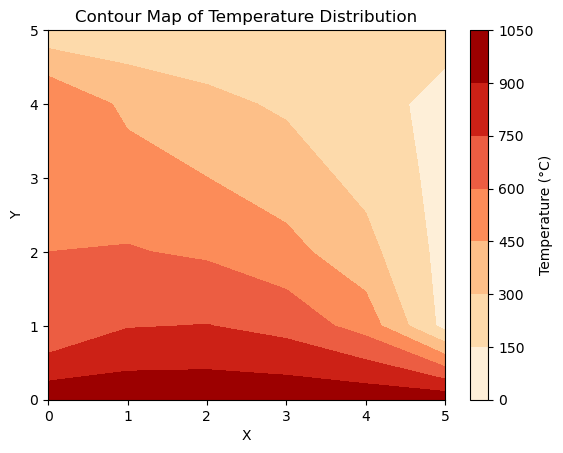

In [1]:
import numpy as np
import matplotlib.pyplot as plt

nx, ny = 6, 6
top_temp = 200
bottom_temp = 1000
left_temp = 600
right_temp = 100

A = np.zeros((nx*ny, nx*ny))
B = np.zeros(nx*ny)

def idx(i, j):
    return i * nx + j

for i in range(ny):
    for j in range(nx):
        k = idx(i, j)
        if i == 0:  # Top boundary
            A[k, k] = 1
            B[k] = top_temp
        elif i == ny-1:  # Bottom boundary
            A[k, k] = 1
            B[k] = bottom_temp
        elif j == 0:  # Left boundary
            A[k, k] = 1
            B[k] = left_temp
        elif j == nx-1:  # Right boundary
            A[k, k] = 1
            B[k] = right_temp
        else:  
            A[k, k] = -4
            A[k, idx(i+1, j)] = 1
            A[k, idx(i-1, j)] = 1
            A[k, idx(i, j+1)] = 1
            A[k, idx(i, j-1)] = 1

T = np.linalg.solve(A, B)
T = T.reshape((ny, nx))

np.set_printoptions(precision=2, linewidth=400)

print("Temperature distribution in the grid:")
print(T)

# X, Y = np.meshgrid(range(nx), range(ny))
# plt.contourf(X, Y[::-1], T, cmap='hot_r')
# plt.colorbar(label='Temperature (°C)')

X, Y = np.meshgrid(range(nx), range(ny))
plt.contourf(X, Y[::-1], T, cmap='OrRd')  
plt.colorbar(label='Temperature (°C)')
plt.title('Contour Map of Temperature Distribution')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

![](media/coursework-09326edb5fef-09326edb.png)
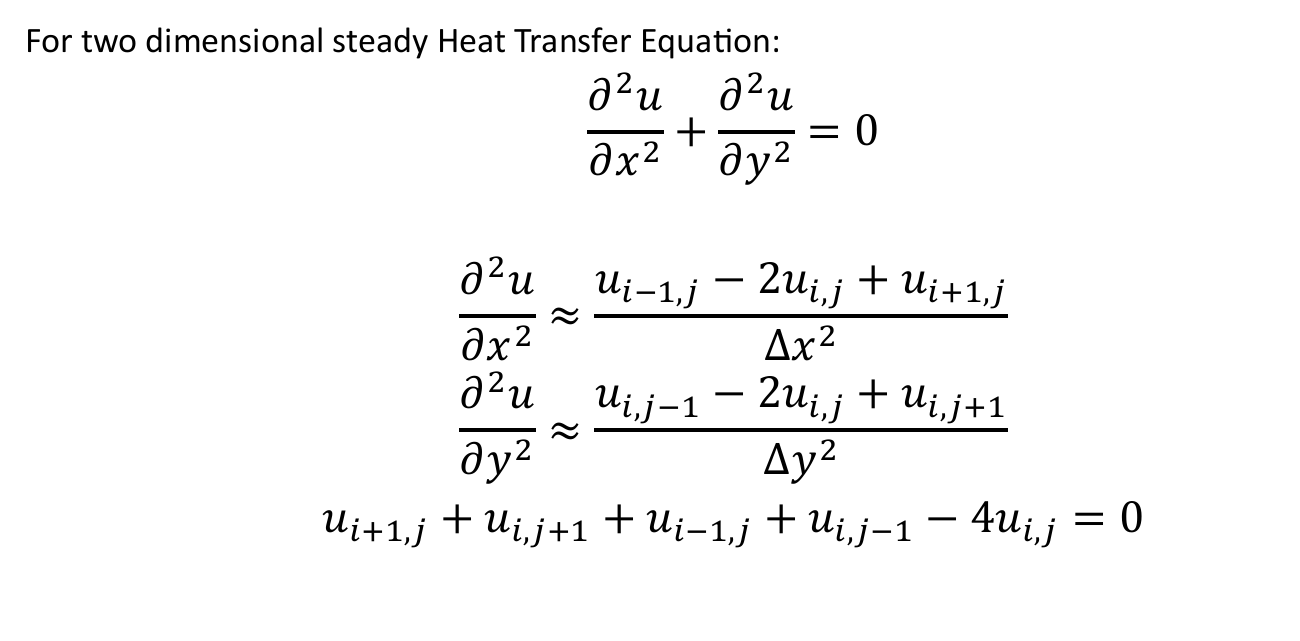

Available colormaps:
['magma', 'inferno', 'plasma', 'viridis', 'cividis', 'twilight', 'twilight_shifted', 'turbo', 'Blues', 'BrBG', 'BuGn', 'BuPu', 'CMRmap', 'GnBu', 'Greens', 'Greys', 'OrRd', 'Oranges', 'PRGn', 'PiYG', 'PuBu', 'PuBuGn', 'PuOr', 'PuRd', 'Purples', 'RdBu', 'RdGy', 'RdPu', 'RdYlBu', 'RdYlGn', 'Reds', 'Spectral', 'Wistia', 'YlGn', 'YlGnBu', 'YlOrBr', 'YlOrRd', 'afmhot', 'autumn', 'binary', 'bone', 'brg', 'bwr', 'cool', 'coolwarm', 'copper', 'cubehelix', 'flag', 'gist_earth', 'gist_gray', 'gist_heat', 'gist_ncar', 'gist_rainbow', 'gist_stern', 'gist_yarg', 'gnuplot', 'gnuplot2', 'gray', 'hot', 'hsv', 'jet', 'nipy_spectral', 'ocean', 'pink', 'prism', 'rainbow', 'seismic', 'spring', 'summer', 'terrain', 'winter', 'Accent', 'Dark2', 'Paired', 'Pastel1', 'Pastel2', 'Set1', 'Set2', 'Set3', 'tab10', 'tab20', 'tab20b', 'tab20c', 'magma_r', 'inferno_r', 'plasma_r', 'viridis_r', 'cividis_r', 'twilight_r', 'twilight_shifted_r', 'turbo_r', 'Blues_r', 'BrBG_r', 'BuGn_r', 'BuPu_r', 'CM

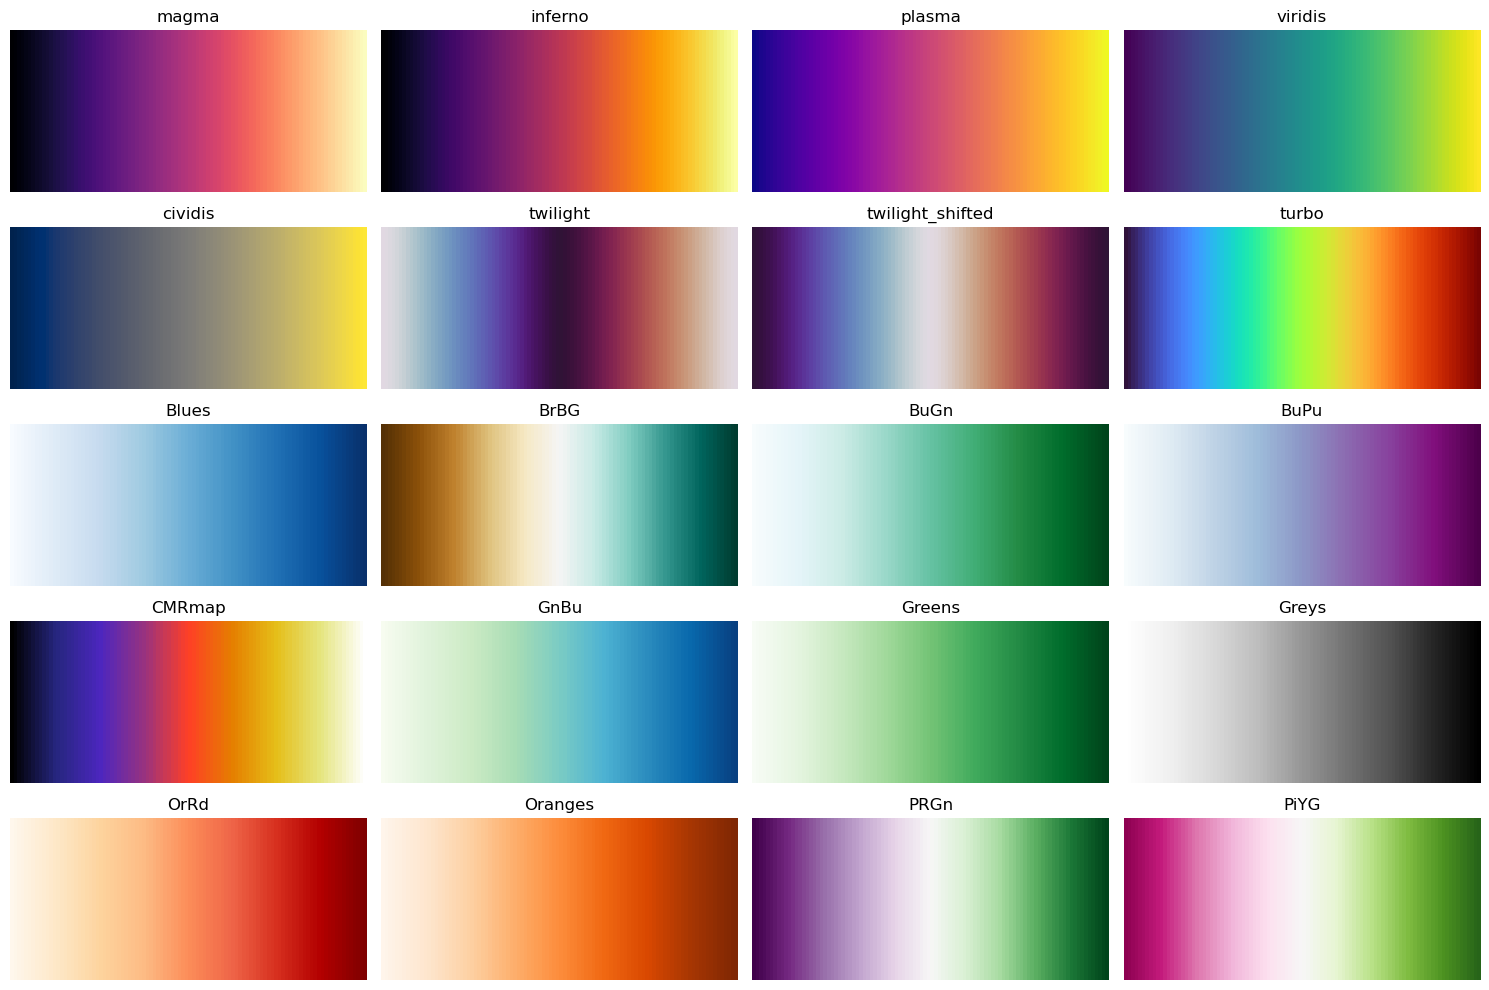

In [2]:
import matplotlib.pyplot as plt

colormaps = plt.colormaps()
print("Available colormaps:")
print(colormaps)

def plot_colormaps(colormaps, ncols=4):
    nrows = len(colormaps) // ncols + (len(colormaps) % ncols > 0)
    fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 10))

    for ax, cmap in zip(axs.flat, colormaps):
        data = np.linspace(0, 1, 100).reshape(1, -1)
        ax.imshow(data, aspect='auto', cmap=cmap)
        ax.set_title(cmap)
        ax.axis('off')

    plt.tight_layout()
    plt.show()

plot_colormaps(colormaps[:20])